# Yuva Task 3: Real-World Student Performance Data Analysis

**Dataset:** UCI Student Performance – Portuguese language course (649 records; 33 attributes in the original dataset). This notebook downloads the dataset from the official UCI repository the first time it runs.

**Objective:** Load, inspect, clean, analyze and visualize student academic performance.

## 1. Import libraries and download the dataset

**Explanation:** Pandas manages tabular data, NumPy supports numerical operations, Matplotlib and Seaborn create charts. The ZIP file is downloaded only if the CSV is not already present.

In [1]:
from pathlib import Path
import zipfile, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / 'data'
OUTPUT_DIR = BASE_DIR / 'outputs'
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

zip_path = DATA_DIR / 'student-performance.zip'
data_path = DATA_DIR / 'student-por.csv'
url = 'https://archive.ics.uci.edu/static/public/320/student+performance.zip'

if not data_path.exists():
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(DATA_DIR)
print('Dataset ready:', data_path)

Dataset ready: c:\Users\Asus\Downloads\Task3_Project\Yuva_Task3_Student_Performance\data\student-por.csv


## 2. Load and understand the dataset

**Explanation:** `read_csv()` loads the semicolon-separated CSV. `head()` previews records, `shape` reports rows and columns, and `info()` shows data types and non-null counts.

In [3]:
df = pd.read_csv(data_path, sep=';')
print(df.head())
print('Shape:', df.shape)
df.info()

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
Shape: (649, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648

## 3. Check missing values and duplicates

**Explanation:** `isnull().sum()` counts missing cells in each column. `duplicated().sum()` counts repeated complete rows. Exact duplicates are removed. Numeric missing values are filled with the median and categorical missing values with the most frequent category. The original UCI dataset is documented as having no missing values, but these checks make the workflow robust.

In [4]:
print('Missing values before cleaning:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().copy()
for col in ['G1', 'G2', 'G3']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
cat_cols = df.select_dtypes(exclude=np.number).columns
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])
print('Missing values after cleaning:\n', df.isnull().sum())
print('Cleaned shape:', df.shape)

Missing values before cleaning:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Duplicate rows: 0
Missing values after cleaning:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel  

## 4. Descriptive statistics

**Explanation:** `describe()` gives count, mean, standard deviation, minimum, quartiles and maximum. Mean is the arithmetic average; median is the middle value; mode is the most frequent value; standard deviation describes spread.

In [5]:
print(df[['age','studytime','absences','G1','G2','G3']].describe().round(2))
print('Mean G3:', round(df['G3'].mean(), 2))
print('Median G3:', round(df['G3'].median(), 2))
print('Mode G3:', df['G3'].mode().iloc[0])
print('Standard deviation G3:', round(df['G3'].std(), 2))
print('Minimum / maximum G3:', df['G3'].min(), '/', df['G3'].max())

          age  studytime  absences      G1      G2      G3
count  649.00     649.00    649.00  649.00  649.00  649.00
mean    16.74       1.93      3.66   11.40   11.57   11.91
std      1.22       0.83      4.64    2.75    2.91    3.23
min     15.00       1.00      0.00    0.00    0.00    0.00
25%     16.00       1.00      0.00   10.00   10.00   10.00
50%     17.00       2.00      2.00   11.00   11.00   12.00
75%     18.00       2.00      6.00   13.00   13.00   14.00
max     22.00       4.00     32.00   19.00   19.00   19.00
Mean G3: 11.91
Median G3: 12.0
Mode G3: 11
Standard deviation G3: 3.23
Minimum / maximum G3: 0 / 19


## 5. Create performance groups

**Explanation:** `pd.cut()` groups final grades into three simple bands for descriptive reporting. These labels are defined for this project and are not official UCI categories.

In [6]:
df['performance_level'] = pd.cut(df['G3'], bins=[-1,9,14,20], labels=['Needs support (0-9)','Moderate (10-14)','High (15-20)'])
print(df['performance_level'].value_counts().sort_index())

performance_level
Needs support (0-9)    100
Moderate (10-14)       418
High (15-20)           131
Name: count, dtype: int64


## 6. Exploratory Data Analysis

**Explanation:** `groupby()` divides records into categories and calculates the mean final grade for each group. The outputs help compare study-time categories, previous failures and gender. These are associations, not proof of cause and effect.

In [7]:
study_grade = df.groupby('studytime', observed=False)['G3'].mean().round(2)
failure_grade = df.groupby('failures')['G3'].mean().round(2)
gender_grade = df.groupby('sex')['G3'].mean().round(2)
print('Average G3 by studytime:\n', study_grade)
print('Average G3 by past failures:\n', failure_grade)
print('Average G3 by gender:\n', gender_grade)
print('Correlation with G3:\n', df[['studytime','absences','failures','G1','G2','G3']].corr(numeric_only=True)['G3'].sort_values(ascending=False).round(3))

Average G3 by studytime:
 studytime
1    10.84
2    12.09
3    13.23
4    13.06
Name: G3, dtype: float64
Average G3 by past failures:
 failures
0    12.51
1     8.64
2     8.81
3     8.07
Name: G3, dtype: float64
Average G3 by gender:
 sex
F    12.25
M    11.41
Name: G3, dtype: float64
Correlation with G3:
 G3           1.000
G2           0.919
G1           0.826
studytime    0.250
absences    -0.091
failures    -0.393
Name: G3, dtype: float64


## 7. Visualizations

Each graph is saved in the `outputs` folder. After running each cell, write 2–3 sentences in your report explaining the pattern visible in the graph.

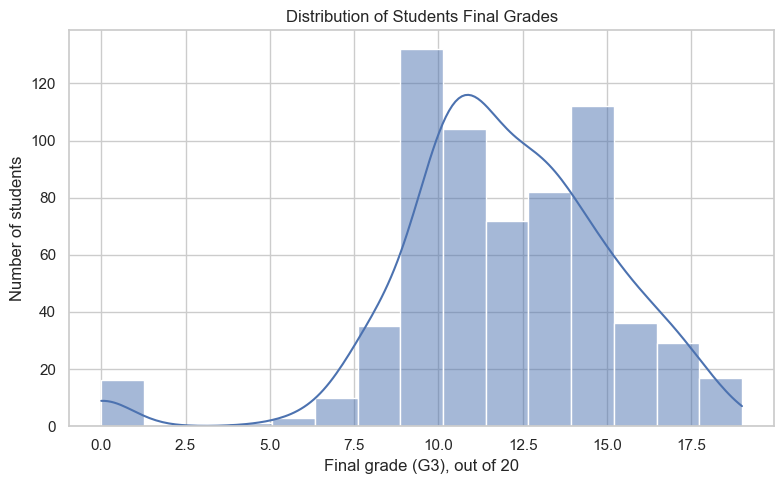

In [8]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(8,5))
sns.histplot(df['G3'], bins=15, kde=True)
plt.title('Distribution of Students Final Grades')
plt.xlabel('Final grade (G3), out of 20'); plt.ylabel('Number of students')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'01_final_grade_distribution.png', dpi=150); plt.show()

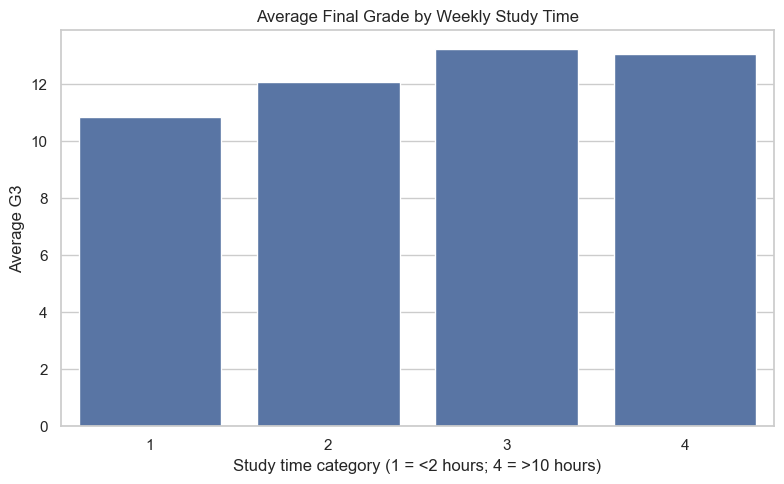

In [9]:
plt.figure(figsize=(8,5))
sns.barplot(x=study_grade.index.astype(str), y=study_grade.values)
plt.title('Average Final Grade by Weekly Study Time')
plt.xlabel('Study time category (1 = <2 hours; 4 = >10 hours)'); plt.ylabel('Average G3')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'02_studytime_vs_grade.png', dpi=150); plt.show()

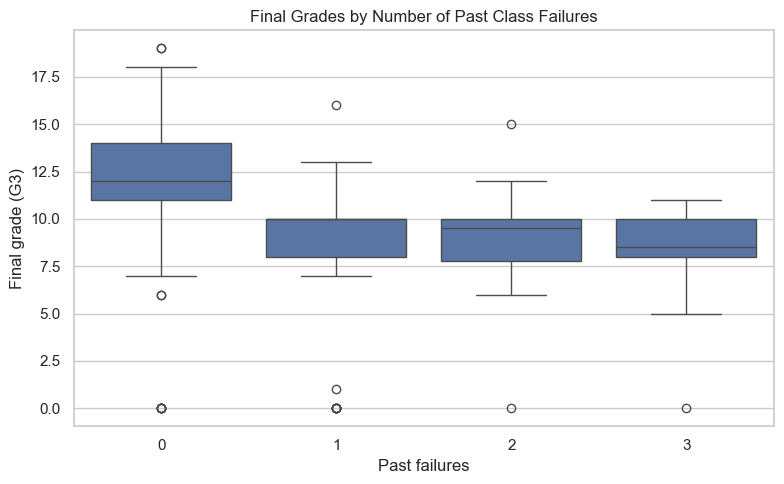

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='failures', y='G3')
plt.title('Final Grades by Number of Past Class Failures')
plt.xlabel('Past failures'); plt.ylabel('Final grade (G3)')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'03_failures_vs_grade.png', dpi=150); plt.show()

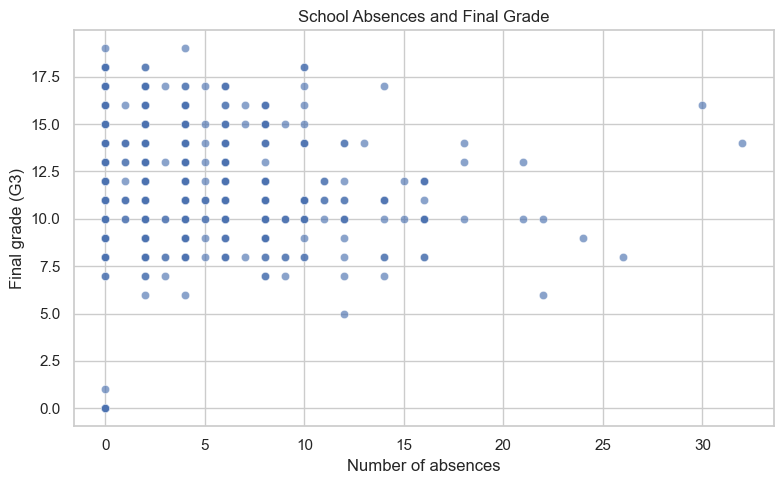

In [11]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='absences', y='G3', alpha=.65)
plt.title('School Absences and Final Grade')
plt.xlabel('Number of absences'); plt.ylabel('Final grade (G3)')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'04_absences_vs_grade.png', dpi=150); plt.show()

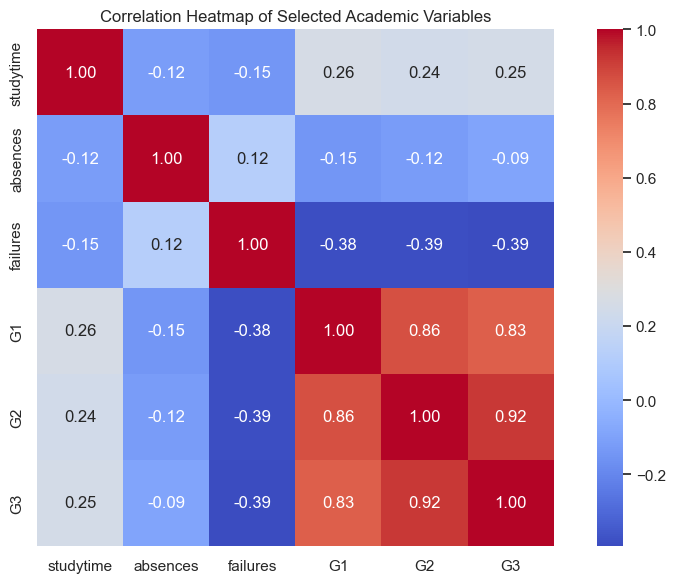

In [13]:
corr = df[['studytime','absences','failures','G1','G2','G3']].corr(numeric_only=True)
plt.figure(figsize=(9,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Heatmap of Selected Academic Variables')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'05_correlation_heatmap.png', dpi=150); plt.show()

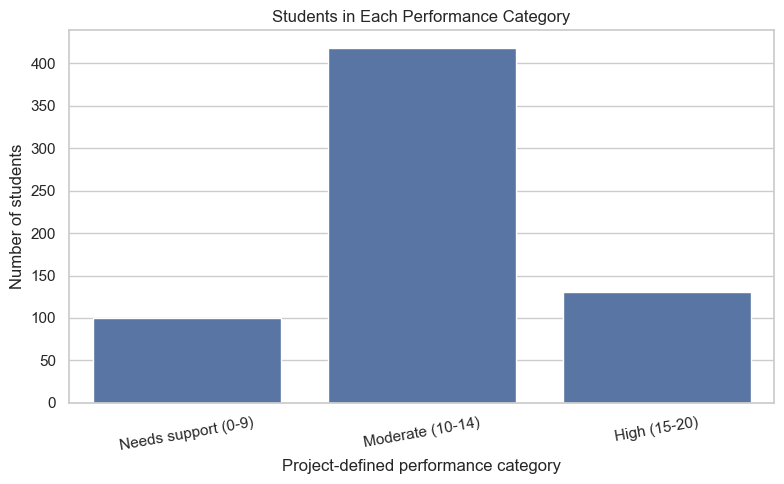

In [14]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='performance_level', order=['Needs support (0-9)','Moderate (10-14)','High (15-20)'])
plt.title('Students in Each Performance Category')
plt.xlabel('Project-defined performance category'); plt.ylabel('Number of students')
plt.xticks(rotation=10); plt.tight_layout()
plt.savefig(OUTPUT_DIR/'06_performance_categories.png', dpi=150); plt.show()

## 8. Export cleaned data and summary

**Explanation:** `to_csv()` saves the cleaned dataset and a small summary table so results can be reused outside the notebook.

In [15]:
df.to_csv(OUTPUT_DIR/'cleaned_student_performance.csv', index=False)
summary = pd.DataFrame({'measure':['student_records','average_final_grade','median_final_grade','minimum_final_grade','maximum_final_grade','average_absences'], 'value':[len(df), round(df.G3.mean(),2), round(df.G3.median(),2), df.G3.min(), df.G3.max(), round(df.absences.mean(),2)]})
summary.to_csv(OUTPUT_DIR/'project_summary.csv', index=False)
print(summary)
print('Saved outputs to:', OUTPUT_DIR.resolve())

               measure   value
0      student_records  649.00
1  average_final_grade   11.91
2   median_final_grade   12.00
3  minimum_final_grade    0.00
4  maximum_final_grade   19.00
5     average_absences    3.66
Saved outputs to: C:\Users\Asus\Downloads\Task3_Project\Yuva_Task3_Student_Performance\outputs


## 9. Findings and conclusion (complete after running)

Use the actual values and charts generated above. Discuss: (1) the distribution and average of G3; (2) whether average G3 changes across study-time groups; (3) how past failures relate to G3; (4) whether absences show a visible relationship with G3; and (5) which variables have the strongest correlations. Do not claim that correlation proves causation. Mention that G1 and G2 are earlier-period grades and are strongly related to G3, as noted by UCI.